# [Lab Session 3](fourier.ipynb)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


In [2]:
cell_img = plt.imread('data/cells.png')
cell_img_resize = resize(cell_img, (256, 256))
plt.imshow(cell_img_resize)
plt.show()

<Figure size 640x480 with 1 Axes>

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [3]:
cell_ft = np.fft.fft2(cell_img_resize)
print(cell_ft.dtype)
print(cell_ft)

complex128
[[ 1.34953203e+04+0.00000000e+00j -6.37424462e+02-3.07641620e+02j
   1.22295427e+02+4.07510107e+02j ... -1.43730595e+02-4.82000542e+02j
   1.22295427e+02-4.07510107e+02j -6.37424462e+02+3.07641620e+02j]
 [-2.44871852e+03-8.21154760e+02j  3.03513248e+03+1.44198390e+03j
   8.02128913e+02+1.35665748e+02j ... -5.77572723e+02+2.31571626e+02j
  -4.86958593e+02-1.59397933e+02j -8.44796516e+00-8.34845909e+02j]
 [ 5.13230081e+01-1.21604799e+02j -7.95647028e+02-1.07553965e+03j
   6.08846590e+02+6.09860471e+01j ...  1.46131127e+02-4.00125145e+00j
  -2.48644208e+02+4.11370701e+01j -6.91764690e+02-1.11374949e+02j]
 ...
 [-3.73820936e+02-5.38601498e+02j -6.63657737e+01-2.36800449e+02j
   2.31162964e+02-4.87350515e+02j ...  3.95064078e+02-1.41987084e+00j
  -6.43746276e+02+3.48827595e+01j  4.38251147e+02-4.43630296e+02j]
 [ 5.13230081e+01+1.21604799e+02j -6.91764690e+02+1.11374949e+02j
  -2.48644208e+02-4.11370701e+01j ...  2.63773928e+02+3.39711693e+02j
   6.08846590e+02-6.09860471e+01j -7

**[Task 1 (c).]()** Extract the phase and amplitude and display them.


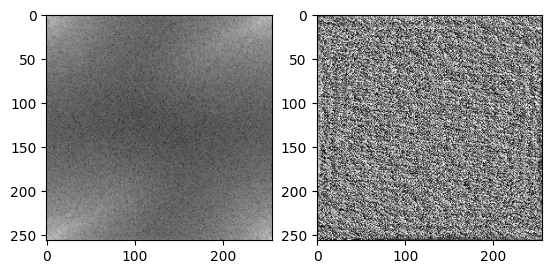

In [4]:
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), "gray")
plt.subplot(1, 2, 2)
plt.imshow(phase, "gray")

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


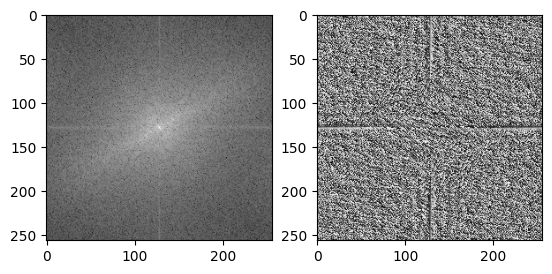

In [5]:
cell_ft_shift = np.fft.fftshift(cell_ft)

amplitude_shift_cell = np.abs(cell_ft_shift)
phase_shift_cell = np.angle(cell_ft_shift)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_shift_cell), "gray")
plt.subplot(1, 2, 2)
plt.imshow(phase_shift_cell, "gray")

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


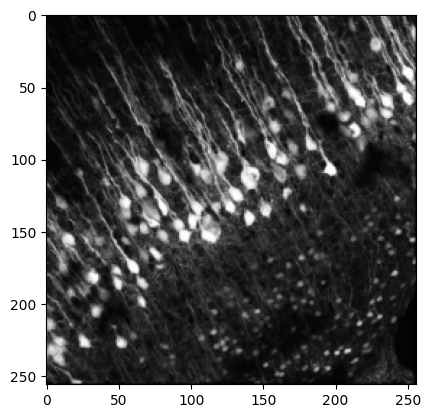

In [6]:
shift_reverse = np.fft.ifftshift(cell_ft_shift)

reverse = np.fft.ifft2(shift_reverse).real

plt.figure()
plt.imshow(reverse, "gray")
plt.show()


---


**[Task 2 (a).]()** Load the brain MR image.


In [7]:
mri = plt.imread("data/brain_mri.png")


**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


complex128


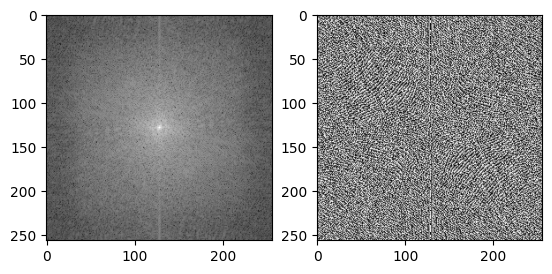

In [ ]:
mri_resize = resize(mri, (256, 256))

mri_ft = np.fft.fft2(mri_resize)
print(mri_ft.dtype)

mri_ft_shift = np.fft.fftshift(mri_ft)

amplitude_shift = np.abs(mri_ft_shift)
phase_shift = np.angle(mri_ft_shift)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_shift), "gray")
plt.subplot(1, 2, 2)
plt.imshow(phase_shift, "gray")

In [9]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


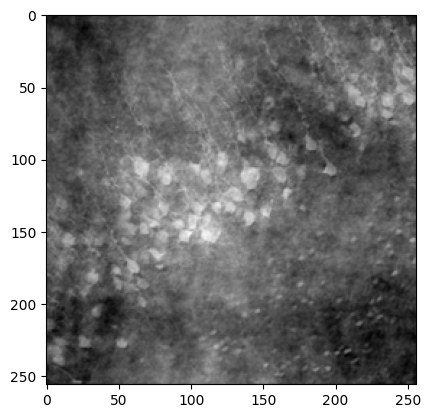

In [12]:
amplitude_brain = amplitude_shift
phase_cell = phase_shift_cell
merged_image_shift = to_complex_array(amplitude_brain, phase_cell)

merge_shift_reverse = np.fft.ifftshift(merged_image_shift)

merged_image = np.fft.ifft2(merge_shift_reverse).real

plt.figure()
plt.imshow(merged_image, "gray")
plt.show()

**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


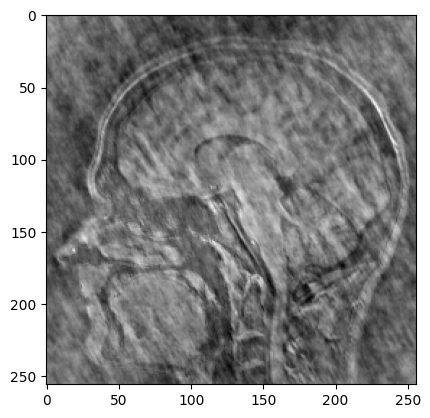

In [13]:
amplitude_cells = amplitude_shift_cell
phase_brain = phase_shift
merged_image_shift = to_complex_array(amplitude_cells, phase_brain)

merge_shift_reverse = np.fft.ifftshift(merged_image_shift)

merged_image = np.fft.ifft2(merge_shift_reverse).real

plt.figure()
plt.imshow(merged_image, "gray")
plt.show()

---


**[Task 3 (a).]()** Create a lowpass filter mask.


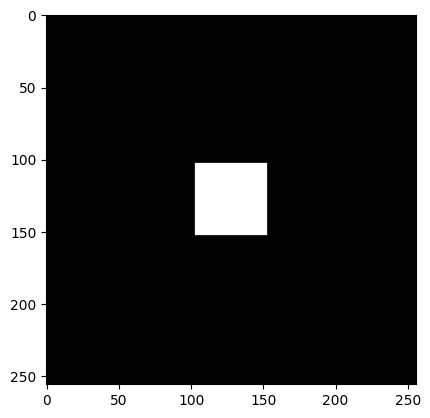

In [21]:
filter_window_size = 50
low_passfilter = np.zeros((256, 256))
low_passfilter[103:153, 103:153] = 1

plt.imshow(low_passfilter, cmap = "gray")
plt.show()

**[Task 3 (b).]()** Create a highpass filter maks.


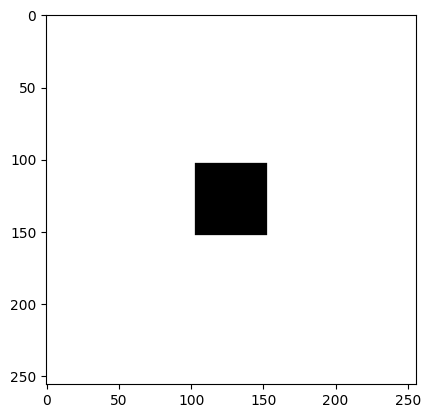

In [22]:
high_passfilter = 1-low_passfilter
plt.imshow(high_passfilter, cmap = "gray")
plt.show()

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


/tmp/ipykernel_2222/905372641.py:9: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(low_ampl), "gray")
/tmp/ipykernel_2222/905372641.py:11: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(high_ampl), "gray")


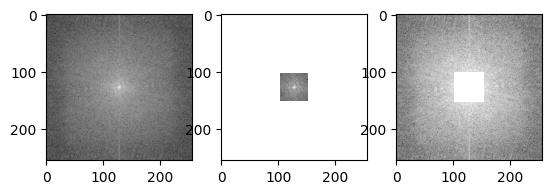

In [23]:
orig_ampl = amplitude_shift
low_ampl = amplitude_shift * low_passfilter
high_ampl = amplitude_shift * high_passfilter

plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(np.log(orig_ampl), "gray")
plt.subplot(1, 3, 2)
plt.imshow(np.log(low_ampl), "gray")
plt.subplot(1, 3, 3)
plt.imshow(np.log(high_ampl), "gray")

**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


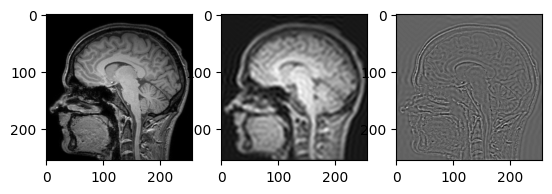

In [24]:
phase_brain = phase_shift
merged_image_shift_orig = to_complex_array(orig_ampl, phase_brain)

merge_shift_reverse_orig = np.fft.ifftshift(merged_image_shift_orig)

merged_image_orig = np.fft.ifft2(merge_shift_reverse_orig).real

merged_image_shift_low = to_complex_array(low_ampl, phase_brain)

merge_shift_reverse_low = np.fft.ifftshift(merged_image_shift_low)

merged_image_low = np.fft.ifft2(merge_shift_reverse_low).real


merged_image_shift_high = to_complex_array(high_ampl, phase_brain)

merge_shift_reverse_high = np.fft.ifftshift(merged_image_shift_high)

merged_image_high = np.fft.ifft2(merge_shift_reverse_high).real

plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(merged_image_orig, "gray")
plt.subplot(1, 3, 2)
plt.imshow(merged_image_low, "gray")
plt.subplot(1, 3, 3)
plt.imshow(merged_image_high, "gray")

---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [ ]:
def own_dft(img):
    dft = np.zeros(img.shape, dtype=complex)
    M, N = img.shape
    for x in range(x, M):
        for y in range(y,N):
            img[x, y] * 

**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


Due to high computational costs, we need to resize the image.


In [ ]:
test_img = resize(brain_img, (40, 40))
plt.imshow(test_img, 'gray')

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


**[Task 4 (f).]()** Round the arrays and compare them again.


**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)
